In [1]:
# ============================================================
# DATA3001 — Project IV
# Region Selection and Data Screening Pipeline
#
# Purpose
# -------
# Compare candidate study regions using the same reproducible
# diagnostics:
#
# 1. Basic data availability
# 2. Spatial observation density
# 3. Temporal gaps
# 4. Continuous trajectory segments
# 5. Temporal coverage
# 6. Era-stratified segment continuity
# 7. Forecast evaluation-origin budget
# 8. Per-drifter sample concentration
#
# IMPORTANT
# ---------
# The 144-hour spacing used below is currently a WORKING
# ASSUMPTION, not a measured decorrelation timescale.
#
# Later, after velocity data (ve/vn) are obtained, estimate
# the Lagrangian integral timescale T_L and replace this value.
# ============================================================

In [2]:
# ============================================================
# 0. Imports
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# ============================================================
# 1. CONFIGURATION
#
# WHEN TESTING NEW REGIONS:
# EDIT ONLY THIS SECTION.
# ============================================================

BASE = os.path.join("data", "regions")

REGIONS = {

    "A": {
        "name": "East China Sea / Kuroshio upstream",
        "path": f"{BASE}/region_A.csv",
        "box": (125, 135, 25, 35),
    },

    "B": {
        "name": "Kuroshio Extension",
        "path": f"{BASE}/region_B.csv",
        "box": (135, 145, 30, 40),
    },

    "C": {
        "name": "Subtropical Countercurrent region",
        "path": f"{BASE}/region_C.csv",
        "box": (135, 145, 20, 30),
    },

    "B_prime": {
        "name": "Revised Kuroshio Extension",
        "path": f"{BASE}/region_B_prime.csv",
        "box": (142, 152, 30, 40),
    },
}

# Forecast design assumptions
LOOKBACK_H = 24
HORIZON_H = 72

# Preliminary independence spacing.
# Replace later using measured Lagrangian decorrelation time.
DECORR_H = 144


ERA_BINS = [
    (1990, 1999),
    (2000, 2004),
    (2005, 2009),
    (2010, 2014),
    (2015, 2019),
    (2020, 2025),
]

In [4]:
# ============================================================
# 2. Helper: load and validate ERDDAP data
# ============================================================

def load_region(path):
    """
    Load one ERDDAP drifter CSV.

    ERDDAP CSV contains:
        row 0 = column names
        row 1 = units

    Therefore skiprows=[1].
    """

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"\nFile not found:\n{path}"
        )

    d = pd.read_csv(path, skiprows=[1])

    required = [
        "ID",
        "time",
        "latitude",
        "longitude",
    ]

    missing = [
        c for c in required
        if c not in d.columns
    ]

    if missing:
        raise ValueError(
            f"Missing required columns: {missing}\n"
            f"Available columns: {list(d.columns)}"
        )

    d["time"] = pd.to_datetime(
        d["time"],
        utc=True,
        errors="coerce"
    )

    # Remove invalid rows
    d = d.dropna(
        subset=[
            "ID",
            "time",
            "latitude",
            "longitude",
        ]
    ).copy()

    # Sort consistently
    d = (
        d.sort_values(["ID", "time"])
         .reset_index(drop=True)
    )

    return d

In [5]:
# ============================================================
# 3. Helper: construct continuous hourly segments
# ============================================================

def get_segments(d):
    """
    Split each drifter trajectory whenever consecutive
    observations are not exactly one hour apart.

    25 hourly observations correspond to 24 hours duration.
    """

    x = d.sort_values(
        ["ID", "time"]
    ).copy()

    gap_seconds = (
        x.groupby("ID")["time"]
         .diff()
         .dt.total_seconds()
    )

    x["gap_hours"] = (
        gap_seconds / 3600
    )

    # New segment:
    # first observation OR gap != 3600 seconds
    x["new_segment"] = (
        gap_seconds.isna()
        | (gap_seconds.round() != 3600)
    )

    x["segment"] = (
        x.groupby("ID")["new_segment"]
         .cumsum()
    )

    seg = (
        x.groupby(["ID", "segment"])
         .agg(
             start=("time", "min"),
             end=("time", "max"),
             n_obs=("time", "size"),
             start_lat=("latitude", "first"),
             start_lon=("longitude", "first"),
             end_lat=("latitude", "last"),
             end_lon=("longitude", "last"),
         )
         .reset_index()
    )

    seg["duration_hours"] = (
        seg["n_obs"] - 1
    )

    seg["start_year"] = (
        seg["start"].dt.year
    )

    return x, seg

In [6]:
# ============================================================
# 4. Helper: era labels
# ============================================================

def era_label(year):

    for lo, hi in ERA_BINS:

        if lo <= year <= hi:
            return f"{lo}-{hi}"

    return "other"

In [7]:
# ============================================================
# 5. Helper: basic data summary
# ============================================================

def basic_summary(d):

    drifter_summary = (
        d.groupby("ID")
         .agg(
             observations=("time", "size"),
             start=("time", "min"),
             end=("time", "max"),
         )
    )

    drifter_summary["duration_days"] = (
        (
            drifter_summary["end"]
            - drifter_summary["start"]
        )
        .dt.total_seconds()
        / 86400
    )

    result = {
        "observations": len(d),
        "unique_drifters": d["ID"].nunique(),
        "start_time": d["time"].min(),
        "end_time": d["time"].max(),
        "median_drifter_duration_days":
            drifter_summary["duration_days"].median(),
        "mean_drifter_duration_days":
            drifter_summary["duration_days"].mean(),
        "drifters_ge_1d":
            int((drifter_summary["duration_days"] >= 1).sum()),
        "drifters_ge_2d":
            int((drifter_summary["duration_days"] >= 2).sum()),
        "drifters_ge_7d":
            int((drifter_summary["duration_days"] >= 7).sum()),
        "drifters_ge_12d":
            int((drifter_summary["duration_days"] >= 12).sum()),
    }

    return result, drifter_summary

In [8]:
# ============================================================
# 6. Helper: gap diagnostics
# ============================================================

def gap_summary(x):

    gaps = x["gap_hours"].dropna()

    result = {
        "n_gaps": len(gaps),

        "median_gap_h":
            gaps.median(),

        "mean_gap_h":
            gaps.mean(),

        "gap_eq_1h":
            int((gaps == 1).sum()),

        "gap_gt_1h":
            int((gaps > 1).sum()),

        "gap_gt_2h":
            int((gaps > 2).sum()),

        "gap_gt_6h":
            int((gaps > 6).sum()),

        "gap_gt_24h":
            int((gaps > 24).sum()),

        "pct_exact_hourly":
            100 * (gaps == 1).mean()
            if len(gaps) else np.nan,
    }

    return result

In [9]:
# ============================================================
# 7. Helper: continuous segment summary
# ============================================================

def segment_summary(seg):

    duration = seg["duration_hours"]

    result = {
        "total_segments":
            len(seg),

        "median_segment_h":
            duration.median(),

        "mean_segment_h":
            duration.mean(),

        "p90_segment_h":
            duration.quantile(0.90),

        "max_segment_h":
            duration.max(),

        "segments_ge_24h":
            int((duration >= 24).sum()),

        "segments_ge_48h":
            int((duration >= 48).sum()),

        "segments_ge_72h":
            int((duration >= 72).sum()),

        "segments_ge_168h":
            int((duration >= 168).sum()),

        "segments_ge_288h":
            int((duration >= 288).sum()),
    }

    return result

In [10]:
# ============================================================
# 8. Helper: temporal coverage
# ============================================================

def year_summary(d):

    y = d.copy()

    y["year"] = y["time"].dt.year

    result = (
        y.groupby("year")
         .agg(
             observations=("ID", "size"),
             unique_drifters=("ID", "nunique"),
         )
         .reset_index()
    )

    return result

In [11]:
# ============================================================
# 9. Helper: era-stratified continuity
# ============================================================

def era_summary(seg):

    s = seg.copy()

    s["era"] = (
        s["start_year"]
        .map(era_label)
    )

    result = (
        s.groupby("era")
         .agg(
             n_segments=(
                 "duration_hours",
                 "size"
             ),

             median_h=(
                 "duration_hours",
                 "median"
             ),

             mean_h=(
                 "duration_hours",
                 "mean"
             ),

             p90_h=(
                 "duration_hours",
                 lambda x:
                 x.quantile(0.90)
             ),

             n_ge_168h=(
                 "duration_hours",
                 lambda x:
                 int((x >= 168).sum())
             ),
         )
    )

    return result

In [12]:
# ============================================================
# 10. Helper: forecast evaluation-origin budget
# ============================================================

def evaluation_budget(
    seg,
    lookback_h=LOOKBACK_H,
    horizon_h=HORIZON_H,
    decorr_h=DECORR_H,
):
    """
    Estimate the number of approximately independent
    forecast evaluation origins.

    Forecast origin requires:

        lookback + horizon

    hours of continuous observations.

    Evaluation origins from the same segment are separated
    by DECORR_H.

    IMPORTANT:
    DECORR_H is currently preliminary.
    """

    need = (
        lookback_h
        + horizon_h
    )

    usable = (
        seg[
            seg["duration_hours"] >= need
        ]
        .copy()
    )

    usable["n_eval"] = (
        1
        + (
            (
                usable["duration_hours"]
                - need
            )
            // decorr_h
        )
    ).astype(int)

    result = {
        "total_segments":
            len(seg),

        "segments_ge_96h":
            len(usable),

        "independent_samples":
            int(usable["n_eval"].sum()),

        "median_samples_per_usable_segment":
            (
                usable["n_eval"].median()
                if len(usable)
                else 0
            ),

        "mean_samples_per_usable_segment":
            (
                usable["n_eval"].mean()
                if len(usable)
                else 0
            ),

        "max_samples_from_one_segment":
            (
                usable["n_eval"].max()
                if len(usable)
                else 0
            ),
    }

    return result, usable

In [13]:
# ============================================================
# 11. Helper: per-drifter sample concentration
# ============================================================

def concentration_summary(usable):

    if len(usable) == 0:

        return {
            "usable_drifters": 0,
            "total_origins": 0,
            "origins_per_drifter_mean": 0,
            "origins_per_drifter_median": 0,
            "top10pct_share": np.nan,
            "top20pct_share": np.nan,
            "largest_drifter_share": np.nan,
            "drifters_ge_10_origins": 0,
            "max_origins_one_drifter": 0,
        }

    per_drifter = (
        usable.groupby("ID")["n_eval"]
              .sum()
              .sort_values(
                  ascending=False
              )
    )

    total = per_drifter.sum()

    n_drifters = len(
        per_drifter
    )

    top10_n = max(
        1,
        int(
            np.ceil(
                n_drifters * 0.10
            )
        )
    )

    top20_n = max(
        1,
        int(
            np.ceil(
                n_drifters * 0.20
            )
        )
    )

    result = {

        "usable_drifters":
            n_drifters,

        "total_origins":
            int(total),

        "origins_per_drifter_mean":
            per_drifter.mean(),

        "origins_per_drifter_median":
            per_drifter.median(),

        "top10pct_share":
            (
                100
                * per_drifter.head(
                    top10_n
                ).sum()
                / total
            ),

        "top20pct_share":
            (
                100
                * per_drifter.head(
                    top20_n
                ).sum()
                / total
            ),

        "largest_drifter_share":
            (
                100
                * per_drifter.iloc[0]
                / total
            ),

        "drifters_ge_10_origins":
            int(
                (
                    per_drifter >= 10
                ).sum()
            ),

        "max_origins_one_drifter":
            int(
                per_drifter.iloc[0]
            ),
    }

    return result

In [14]:
# ============================================================
# 12. Helper: density map
# ============================================================

def plot_density(d, code, info):

    lon_min, lon_max, lat_min, lat_max = (
        info["box"]
    )

    plt.figure(
        figsize=(8, 7)
    )

    plt.hist2d(
        d["longitude"],
        d["latitude"],
        bins=50,
        cmap="viridis",
    )

    plt.colorbar(
        label="Number of observations"
    )

    plt.xlabel(
        "Longitude"
    )

    plt.ylabel(
        "Latitude"
    )

    plt.title(
        f"Candidate {code}: Observation Density\n"
        f"{info['name']}"
    )

    plt.xlim(
        lon_min,
        lon_max
    )

    plt.ylim(
        lat_min,
        lat_max
    )

    plt.tight_layout()

    plt.show()

In [15]:
# ============================================================
# 13. Helper: yearly drifter plot
# ============================================================

def plot_yearly_drifters(
    ys,
    code,
    info
):

    plt.figure(
        figsize=(10, 5)
    )

    plt.bar(
        ys["year"],
        ys["unique_drifters"]
    )

    plt.xlabel(
        "Year"
    )

    plt.ylabel(
        "Number of unique drifters"
    )

    plt.title(
        f"Candidate {code}: Unique Drifters by Year\n"
        f"{info['name']}"
    )

    plt.xticks(
        rotation=45
    )

    plt.tight_layout()

    plt.show()



Candidate A: East China Sea / Kuroshio upstream

--- 1. BASIC DATA AVAILABILITY ---
observations                       : 562944
unique_drifters                    : 521
start_time                         : 1994-07-10 12:00:00+00:00
end_time                           : 2022-10-31 00:00:00+00:00
median_drifter_duration_days       : 39.083333333333336
mean_drifter_duration_days         : 84.46361164427384
drifters_ge_1d                     : 480
drifters_ge_2d                     : 472
drifters_ge_7d                     : 443
drifters_ge_12d                    : 422

--- 2. SPATIAL DENSITY ---


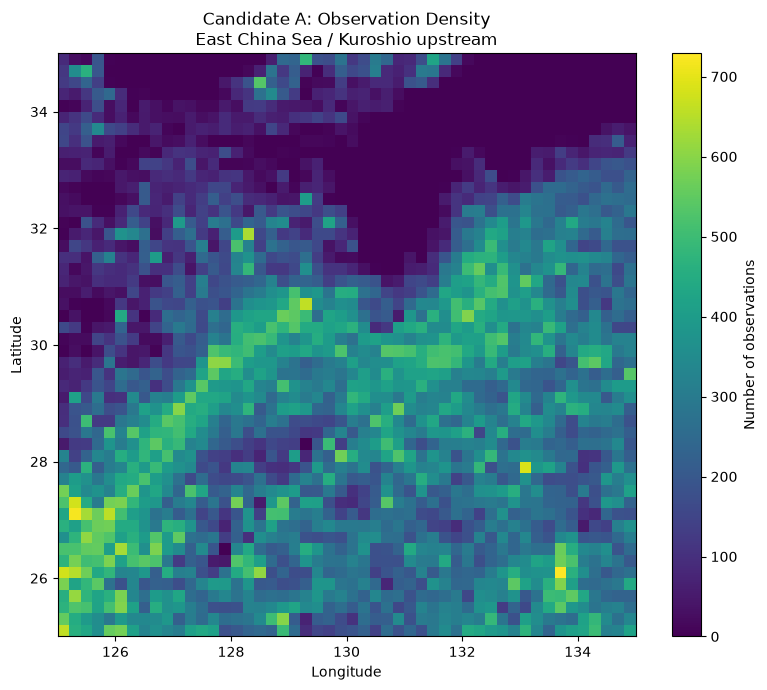


--- 3. TEMPORAL GAPS ---
n_gaps                             : 562423
median_gap_h                       : 1.00
mean_gap_h                         : 1.88
gap_eq_1h                          : 560886
gap_gt_1h                          : 1537
gap_gt_2h                          : 1519
gap_gt_6h                          : 1472
gap_gt_24h                         : 751
pct_exact_hourly                   : 99.73

--- 4. CONTINUOUS SEGMENTS ---
total_segments                     : 2058
median_segment_h                   : 73.00
mean_segment_h                     : 272.54
p90_segment_h                      : 809.70
max_segment_h                      : 3569
segments_ge_24h                    : 1392
segments_ge_48h                    : 1178
segments_ge_72h                    : 1038
segments_ge_168h                   : 746
segments_ge_288h                   : 567

--- 5. TEMPORAL COVERAGE ---
 year  observations  unique_drifters
 1994           305                1
 1998            42              

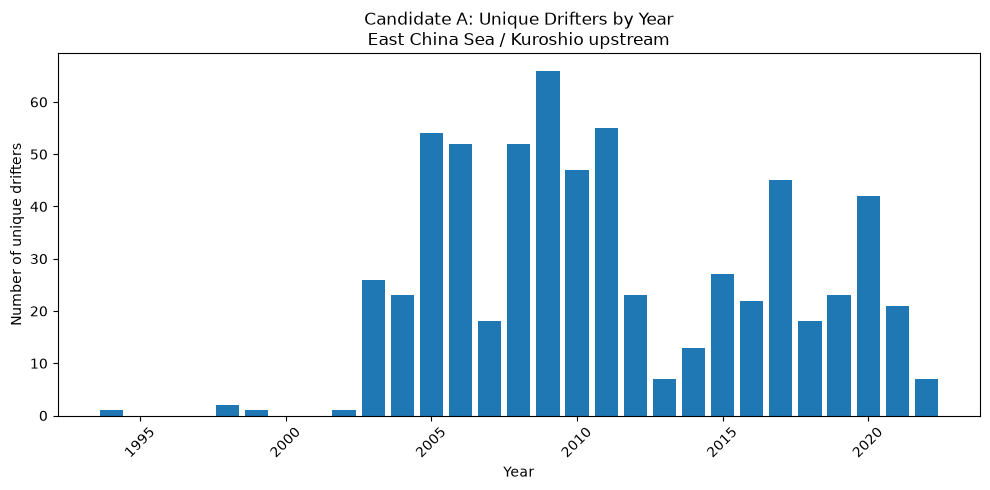


--- 6. ERA-STRATIFIED CONTINUITY ---
           n_segments  median_h      mean_h   p90_h  n_ge_168h
era                                                           
1990-1999           7      12.0   98.857143   312.0          2
2000-2004          78     200.5  475.820513  1419.7         40
2005-2009         954      43.0  193.203354   590.7        276
2010-2014         464      71.0  269.443966   834.9        158
2015-2019         418     143.5  388.452153  1074.1        200
2020-2025         137     190.0  374.956204   939.6         70

--- 7. EVALUATION-ORIGIN BUDGET ---
Lookback = 24 h
Horizon  = 72 h
Preliminary spacing = 144 h
total_segments                          : 2058
segments_ge_96h                         : 935
independent_samples                     : 3592
median_samples_per_usable_segment       : 3.00
mean_samples_per_usable_segment         : 3.84
max_samples_from_one_segment            : 25

--- 8. PER-DRIFTER SAMPLE CONCENTRATION ---
usable_drifters                      

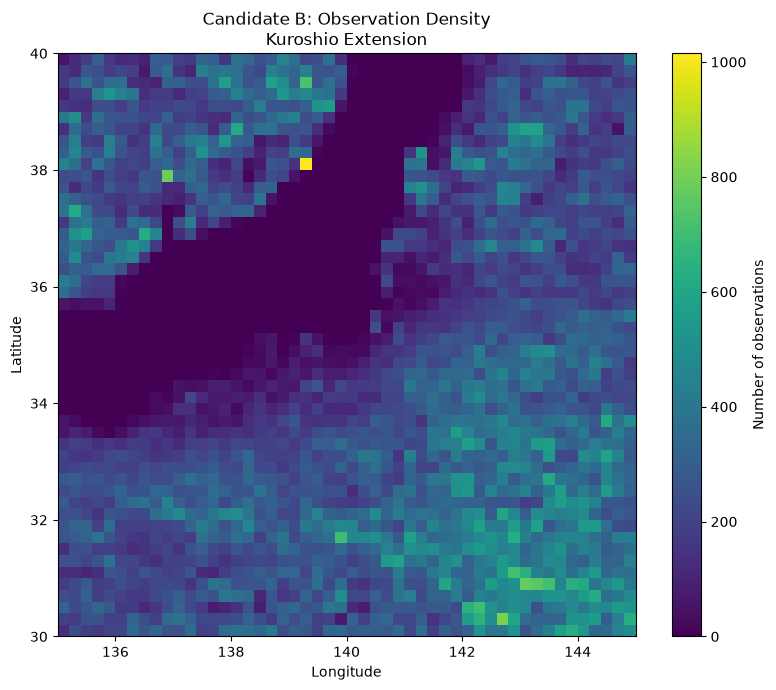


--- 3. TEMPORAL GAPS ---
n_gaps                             : 550216
median_gap_h                       : 1.00
mean_gap_h                         : 2.35
gap_eq_1h                          : 548575
gap_gt_1h                          : 1641
gap_gt_2h                          : 1618
gap_gt_6h                          : 1584
gap_gt_24h                         : 949
pct_exact_hourly                   : 99.70

--- 4. CONTINUOUS SEGMENTS ---
total_segments                     : 2186
median_segment_h                   : 78.00
mean_segment_h                     : 250.95
p90_segment_h                      : 696.50
max_segment_h                      : 3457
segments_ge_24h                    : 1562
segments_ge_48h                    : 1304
segments_ge_72h                    : 1123
segments_ge_168h                   : 798
segments_ge_288h                   : 578

--- 5. TEMPORAL COVERAGE ---
 year  observations  unique_drifters
 1990           521                2
 1994           288              

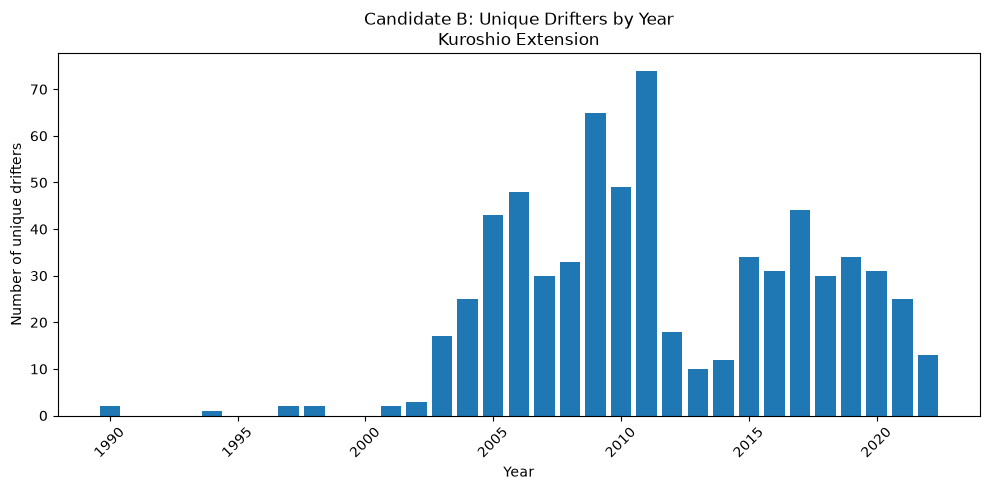


--- 6. ERA-STRATIFIED CONTINUITY ---
           n_segments  median_h      mean_h  p90_h  n_ge_168h
era                                                          
1990-1999          11     255.0  310.272727  680.0          8
2000-2004         128     191.0  336.187500  842.5         70
2005-2009         916      48.0  193.994541  561.5        260
2010-2014         482      77.0  236.614108  666.4        176
2015-2019         430     145.5  358.795349  909.3        198
2020-2025         219      86.0  256.168950  651.0         86

--- 7. EVALUATION-ORIGIN BUDGET ---
Lookback = 24 h
Horizon  = 72 h
Preliminary spacing = 144 h
total_segments                          : 2186
segments_ge_96h                         : 1017
independent_samples                     : 3460
median_samples_per_usable_segment       : 2.00
mean_samples_per_usable_segment         : 3.40
max_samples_from_one_segment            : 24

--- 8. PER-DRIFTER SAMPLE CONCENTRATION ---
usable_drifters                         : 48

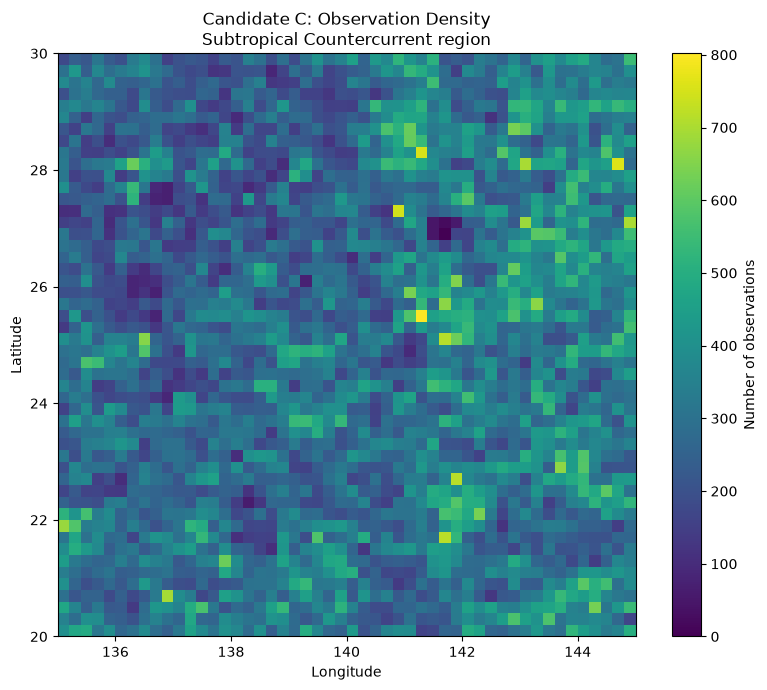


--- 3. TEMPORAL GAPS ---
n_gaps                             : 767562
median_gap_h                       : 1.00
mean_gap_h                         : 1.93
gap_eq_1h                          : 766042
gap_gt_1h                          : 1520
gap_gt_2h                          : 1495
gap_gt_6h                          : 1432
gap_gt_24h                         : 871
pct_exact_hourly                   : 99.80

--- 4. CONTINUOUS SEGMENTS ---
total_segments                     : 1923
median_segment_h                   : 87.00
mean_segment_h                     : 398.36
p90_segment_h                      : 1253.20
max_segment_h                      : 8084
segments_ge_24h                    : 1335
segments_ge_48h                    : 1150
segments_ge_72h                    : 1045
segments_ge_168h                   : 738
segments_ge_288h                   : 576

--- 5. TEMPORAL COVERAGE ---
 year  observations  unique_drifters
 2002           258                1
 2003          8670             

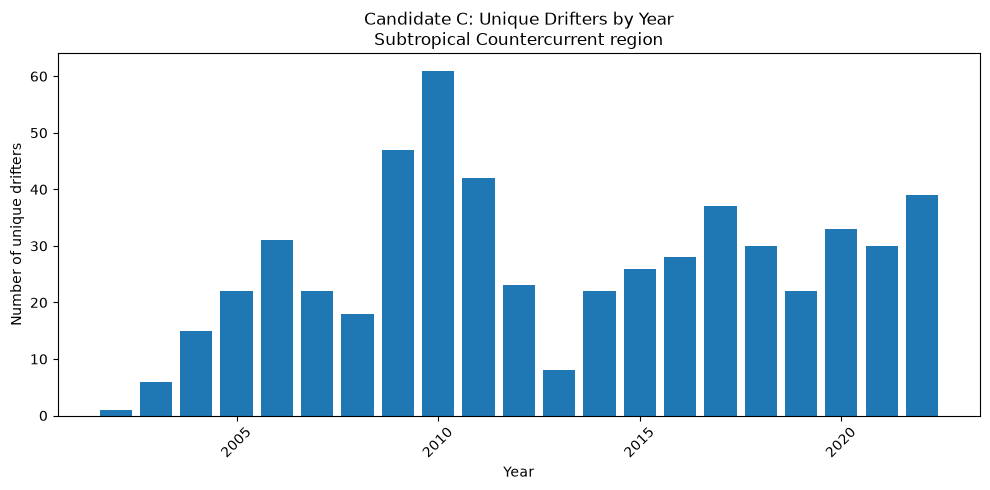


--- 6. ERA-STRATIFIED CONTINUITY ---
           n_segments  median_h      mean_h   p90_h  n_ge_168h
era                                                           
2000-2004          74     189.0  391.878378  1094.7         39
2005-2009         618      55.0  349.566343  1104.9        191
2010-2014         494      75.5  391.459514   996.5        186
2015-2019         462     118.5  449.640693  1389.7        199
2020-2025         275     138.0  435.985455  1401.2        123

--- 7. EVALUATION-ORIGIN BUDGET ---
Lookback = 24 h
Horizon  = 72 h
Preliminary spacing = 144 h
total_segments                          : 1923
segments_ge_96h                         : 927
independent_samples                     : 5026
median_samples_per_usable_segment       : 3.00
mean_samples_per_usable_segment         : 5.42
max_samples_from_one_segment            : 56

--- 8. PER-DRIFTER SAMPLE CONCENTRATION ---
usable_drifters                         : 365
total_origins                           : 5026
origins

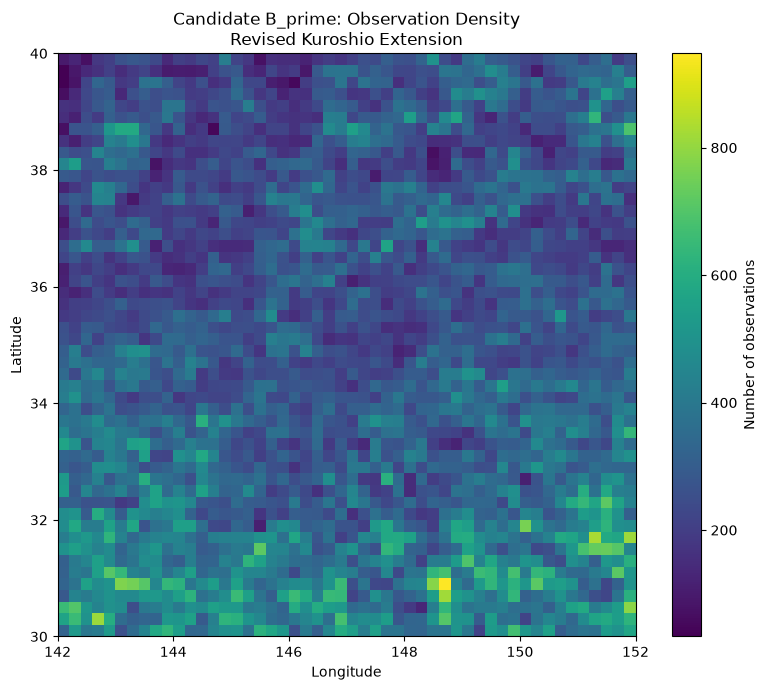


--- 3. TEMPORAL GAPS ---
n_gaps                             : 798163
median_gap_h                       : 1.00
mean_gap_h                         : 2.01
gap_eq_1h                          : 796228
gap_gt_1h                          : 1935
gap_gt_2h                          : 1900
gap_gt_6h                          : 1841
gap_gt_24h                         : 1096
pct_exact_hourly                   : 99.76

--- 4. CONTINUOUS SEGMENTS ---
total_segments                     : 2451
median_segment_h                   : 94.00
mean_segment_h                     : 324.86
p90_segment_h                      : 972.00
max_segment_h                      : 5833
segments_ge_24h                    : 1787
segments_ge_48h                    : 1538
segments_ge_72h                    : 1337
segments_ge_168h                   : 986
segments_ge_288h                   : 730

--- 5. TEMPORAL COVERAGE ---
 year  observations  unique_drifters
 1990          4614                2
 1994          1168             

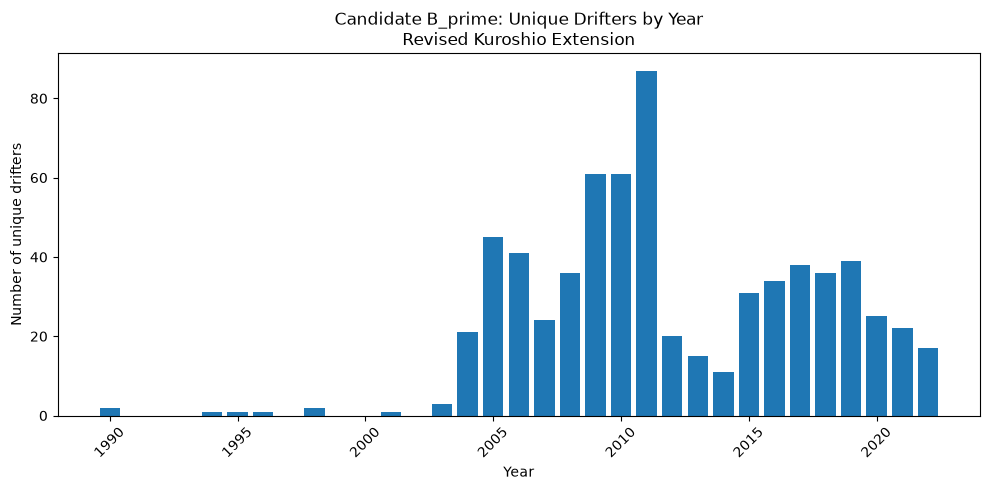


--- 6. ERA-STRATIFIED CONTINUITY ---
           n_segments  median_h      mean_h   p90_h  n_ge_168h
era                                                           
1990-1999          18      95.0  325.611111   936.0          8
2000-2004         109     140.0  336.706422  1003.0         52
2005-2009         856      58.0  241.860981   728.5        280
2010-2014         685      85.0  330.608759  1011.2        271
2015-2019         536     163.0  416.957090  1121.5        264
2020-2025         247     122.0  391.404858  1164.4        111

--- 7. EVALUATION-ORIGIN BUDGET ---
Lookback = 24 h
Horizon  = 72 h
Preliminary spacing = 144 h
total_segments                          : 2451
segments_ge_96h                         : 1218
independent_samples                     : 5125
median_samples_per_usable_segment       : 2.00
mean_samples_per_usable_segment         : 4.21
max_samples_from_one_segment            : 40

--- 8. PER-DRIFTER SAMPLE CONCENTRATION ---
usable_drifters                     

In [16]:
# ============================================================
# 14. RUN PIPELINE
# ============================================================

all_data = {}
all_segments = {}

basic_results = {}
gap_results = {}
segment_results = {}
year_results = {}
era_results = {}
budget_results = {}
concentration_results = {}


for code, info in REGIONS.items():

    print("\n")
    print("=" * 72)
    print(
        f"Candidate {code}: {info['name']}"
    )
    print("=" * 72)

    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    d = load_region(
        info["path"]
    )

    x, seg = get_segments(
        d
    )

    all_data[code] = d
    all_segments[code] = seg

    # --------------------------------------------------------
    # Basic summary
    # --------------------------------------------------------

    basic, drifter_summary = (
        basic_summary(d)
    )

    basic_results[code] = basic

    print(
        "\n--- 1. BASIC DATA AVAILABILITY ---"
    )

    for k, v in basic.items():
        print(
            f"{k:<35}: {v}"
        )

    # --------------------------------------------------------
    # Density
    # --------------------------------------------------------

    print(
        "\n--- 2. SPATIAL DENSITY ---"
    )

    plot_density(
        d,
        code,
        info
    )

    # --------------------------------------------------------
    # Gaps
    # --------------------------------------------------------

    gaps = gap_summary(
        x
    )

    gap_results[code] = gaps

    print(
        "\n--- 3. TEMPORAL GAPS ---"
    )

    for k, v in gaps.items():

        if isinstance(
            v,
            (float, np.floating)
        ):
            print(
                f"{k:<35}: {v:.2f}"
            )
        else:
            print(
                f"{k:<35}: {v}"
            )

    # --------------------------------------------------------
    # Segments
    # --------------------------------------------------------

    ss = segment_summary(
        seg
    )

    segment_results[code] = ss

    print(
        "\n--- 4. CONTINUOUS SEGMENTS ---"
    )

    for k, v in ss.items():

        if isinstance(
            v,
            (float, np.floating)
        ):
            print(
                f"{k:<35}: {v:.2f}"
            )
        else:
            print(
                f"{k:<35}: {v}"
            )

    # --------------------------------------------------------
    # Year coverage
    # --------------------------------------------------------

    ys = year_summary(
        d
    )

    year_results[code] = ys

    print(
        "\n--- 5. TEMPORAL COVERAGE ---"
    )

    print(
        ys.to_string(
            index=False
        )
    )

    plot_yearly_drifters(
        ys,
        code,
        info
    )

    # --------------------------------------------------------
    # Era
    # --------------------------------------------------------

    es = era_summary(
        seg
    )

    era_results[code] = es

    print(
        "\n--- 6. ERA-STRATIFIED CONTINUITY ---"
    )

    print(
        es.to_string()
    )

    # --------------------------------------------------------
    # Evaluation budget
    # --------------------------------------------------------

    budget, usable = (
        evaluation_budget(seg)
    )

    budget_results[code] = budget

    print(
        "\n--- 7. EVALUATION-ORIGIN BUDGET ---"
    )

    print(
        f"Lookback = {LOOKBACK_H} h"
    )

    print(
        f"Horizon  = {HORIZON_H} h"
    )

    print(
        f"Preliminary spacing = {DECORR_H} h"
    )

    for k, v in budget.items():

        if isinstance(
            v,
            (float, np.floating)
        ):
            print(
                f"{k:<40}: {v:.2f}"
            )
        else:
            print(
                f"{k:<40}: {v}"
            )

    # --------------------------------------------------------
    # Concentration
    # --------------------------------------------------------

    concentration = (
        concentration_summary(
            usable
        )
    )

    concentration_results[
        code
    ] = concentration

    print(
        "\n--- 8. PER-DRIFTER SAMPLE CONCENTRATION ---"
    )

    for k, v in concentration.items():

        if isinstance(
            v,
            (float, np.floating)
        ):
            print(
                f"{k:<40}: {v:.2f}"
            )
        else:
            print(
                f"{k:<40}: {v}"
            )

In [17]:
# ============================================================
# 15. SIDE-BY-SIDE COMPARISON TABLES
# ============================================================

basic_table = (
    pd.DataFrame(
        basic_results
    ).T
)

gap_table = (
    pd.DataFrame(
        gap_results
    ).T
)

segment_table = (
    pd.DataFrame(
        segment_results
    ).T
)

budget_table = (
    pd.DataFrame(
        budget_results
    ).T
)

concentration_table = (
    pd.DataFrame(
        concentration_results
    ).T
)


print("\n")
print("=" * 72)
print("TABLE 1 — BASIC DATA AVAILABILITY")
print("=" * 72)
print(
    basic_table.to_string()
)


print("\n")
print("=" * 72)
print("TABLE 2 — TEMPORAL GAPS")
print("=" * 72)
print(
    gap_table.to_string()
)


print("\n")
print("=" * 72)
print("TABLE 3 — CONTINUOUS SEGMENTS")
print("=" * 72)
print(
    segment_table.to_string()
)


print("\n")
print("=" * 72)
print("TABLE 4 — EVALUATION-ORIGIN BUDGET")
print("=" * 72)
print(
    budget_table.to_string()
)


print("\n")
print("=" * 72)
print("TABLE 5 — SAMPLE CONCENTRATION")
print("=" * 72)
print(
    concentration_table.to_string()
)



TABLE 1 — BASIC DATA AVAILABILITY
        observations unique_drifters                 start_time                   end_time median_drifter_duration_days mean_drifter_duration_days drifters_ge_1d drifters_ge_2d drifters_ge_7d drifters_ge_12d
A             562944             521  1994-07-10 12:00:00+00:00  2022-10-31 00:00:00+00:00                    39.083333                  84.463612            480            472            443             422
B             550761             545  1990-03-11 11:00:00+00:00  2022-10-29 16:00:00+00:00                       39.625                  98.993884            533            521            489             428
C             767965             403  2002-04-17 03:00:00+00:00  2022-10-31 00:00:00+00:00                       92.875                 153.461849            399            390            364             348
B_prime       798679             516  1990-03-18 16:00:00+00:00  2022-10-31 00:00:00+00:00                      57.8125             

In [18]:
# ============================================================
# 16. COMPACT REGION-SELECTION TABLE
# ============================================================

decision_table = pd.DataFrame(
    index=list(REGIONS.keys())
)


decision_table["observations"] = [
    basic_results[r][
        "observations"
    ]
    for r in decision_table.index
]


decision_table["unique_drifters"] = [
    basic_results[r][
        "unique_drifters"
    ]
    for r in decision_table.index
]


decision_table["pct_exact_hourly"] = [
    gap_results[r][
        "pct_exact_hourly"
    ]
    for r in decision_table.index
]


decision_table["continuous_segments"] = [
    segment_results[r][
        "total_segments"
    ]
    for r in decision_table.index
]


decision_table["segments_ge_48h"] = [
    segment_results[r][
        "segments_ge_48h"
    ]
    for r in decision_table.index
]


decision_table["segments_ge_168h"] = [
    segment_results[r][
        "segments_ge_168h"
    ]
    for r in decision_table.index
]


decision_table["segments_ge_288h"] = [
    segment_results[r][
        "segments_ge_288h"
    ]
    for r in decision_table.index
]


decision_table["usable_drifters"] = [
    concentration_results[r][
        "usable_drifters"
    ]
    for r in decision_table.index
]


decision_table["evaluation_origins"] = [
    budget_results[r][
        "independent_samples"
    ]
    for r in decision_table.index
]


decision_table["origins_per_drifter"] = [
    concentration_results[r][
        "origins_per_drifter_mean"
    ]
    for r in decision_table.index
]


decision_table["top10pct_share"] = [
    concentration_results[r][
        "top10pct_share"
    ]
    for r in decision_table.index
]


print("\n")
print("=" * 72)
print("FINAL REGION-SELECTION DIAGNOSTIC TABLE")
print("=" * 72)

print(
    decision_table.round(2).to_string()
)



FINAL REGION-SELECTION DIAGNOSTIC TABLE
         observations  unique_drifters  pct_exact_hourly  continuous_segments  segments_ge_48h  segments_ge_168h  segments_ge_288h  usable_drifters  evaluation_origins  origins_per_drifter  top10pct_share
A              562944              521             99.73                 2058             1178               746               567              448                3592                 8.02           30.35
B              550761              545             99.70                 2186             1304               798               578              482                3460                 7.18           32.23
C              767965              403             99.80                 1923             1150               738               576              365                5026                13.77           31.68
B_prime        798679              516             99.76                 2451             1538               986               730        

In [19]:
# ============================================================
# 17. ERA TABLES
# ============================================================

print("\n")
print("=" * 72)
print("ERA-STRATIFIED RESULTS")
print("=" * 72)

for code in REGIONS:

    print("\n")
    print(
        f"Candidate {code}: "
        f"{REGIONS[code]['name']}"
    )

    print("-" * 72)

    print(
        era_results[
            code
        ].to_string()
    )



ERA-STRATIFIED RESULTS


Candidate A: East China Sea / Kuroshio upstream
------------------------------------------------------------------------
           n_segments  median_h      mean_h   p90_h  n_ge_168h
era                                                           
1990-1999           7      12.0   98.857143   312.0          2
2000-2004          78     200.5  475.820513  1419.7         40
2005-2009         954      43.0  193.203354   590.7        276
2010-2014         464      71.0  269.443966   834.9        158
2015-2019         418     143.5  388.452153  1074.1        200
2020-2025         137     190.0  374.956204   939.6         70


Candidate B: Kuroshio Extension
------------------------------------------------------------------------
           n_segments  median_h      mean_h  p90_h  n_ge_168h
era                                                          
1990-1999          11     255.0  310.272727  680.0          8
2000-2004         128     191.0  336.187500  842.5     

In [20]:
# ============================================================
# 18. FINAL NOTES
# ============================================================

print("\n")
print("=" * 72)
print("IMPORTANT INTERPRETATION NOTES")
print("=" * 72)

print(
    """
1. Raw observations are NOT independent samples.

2. Continuous segments are more informative than raw row counts
   for trajectory forecasting.

3. A forecast origin currently requires:
       24 h lookback + 72 h forecast horizon = 96 h continuous data.

4. The 144 h spacing between evaluation origins is preliminary.
   It must later be replaced by a value informed by the measured
   Lagrangian velocity decorrelation / integral timescale.

5. 'Independent_samples' therefore means approximately spaced
   evaluation origins under the current working assumption,
   NOT formally independent statistical observations.

6. Per-drifter concentration is reported because many evaluation
   origins may come from the same drifter.

7. Train / calibration / test splitting must NOT be performed
   randomly at the row or forecast-origin level.

8. Later stages should use drifter-level or correlation-cluster-level
   splitting to reduce information leakage.

9. Additional GDP variables should later be obtained where available:
       - ve
       - vn
       - drogue status / drogue-loss information
       - location type
       - uncertainty / error variables

10. Final region selection should combine:
       (a) data adequacy,
       (b) effective independent sampling,
       (c) spatial/temporal coverage,
       (d) oceanographic interpretability,
       (e) relevance to the forecasting and uncertainty task.
"""
)



IMPORTANT INTERPRETATION NOTES

1. Raw observations are NOT independent samples.

2. Continuous segments are more informative than raw row counts
   for trajectory forecasting.

3. A forecast origin currently requires:
       24 h lookback + 72 h forecast horizon = 96 h continuous data.

4. The 144 h spacing between evaluation origins is preliminary.
   It must later be replaced by a value informed by the measured
   Lagrangian velocity decorrelation / integral timescale.

5. 'Independent_samples' therefore means approximately spaced
   evaluation origins under the current working assumption,
   NOT formally independent statistical observations.

6. Per-drifter concentration is reported because many evaluation
   origins may come from the same drifter.

7. Train / calibration / test splitting must NOT be performed
   randomly at the row or forecast-origin level.

8. Later stages should use drifter-level or correlation-cluster-level
   splitting to reduce information leakage.

9. Addi